# 27 Bestes Viertel als Maßstab und Lern-/Testprüfung

- Der Netzvergleich (Notebook 20) misst jede Station am Median. Zeigt das beste Viertel je Kennzahl als zweiter Maßstab mehr, wenn schon die typische Station schlecht läuft?
- Hätte ein vor den Begehungen gelernter, eingefrorener Maßstab die Stationen mit späterem Befund erkannt, und rücken begangene Stationen danach näher an die besten heran?
- Lücke: Abstand zum Median des besten Viertels, geteilt durch den Abstand der typischen Station (Median) dazu. 0 heißt so gut wie das beste Viertel, 1 so weit weg wie die typische Station. Potenzialwert: Mittel der Lücken über die Score-Kennzahlen.
- Stufen: unter 1 gering, 1 bis unter 2 mittel, ab 2 hoch (Setzung, vom Team zu bestätigen). Die Priorität bleibt, das Potenzial steht daneben.
- Daten aus Notebook 00, Logik in `src/netzvergleich.py` (`bestwert`, `grenzen_lernen`, `grenzen_anwenden`, `potenzial_je_winter`) und `src/stationsblatt.py`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import befundcodes as bc
from src import netzvergleich as nv
from src import stationsblatt as bl

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

t0 = time.time()
e = bl.eingaben(ROOT)
erg = bl.rechne(e["serien"], e["termine"], e["anschlusswerte"], e["bhkw"],
                e["ohne_datum"], baujahr=e["baujahr"])
tab = erg["tabelle"]
kz = erg["kennzahlen"]
ref_aus = tuple(sorted(erg["bhkw"]))
termine = erg["termine"]
ohne_datum = erg["ohne_datum"]
labels = bc.labels_je_zaehler(bc.kodiere_begehungen())
befund = dict(zip(labels["meter"].astype(int), labels["n_befunde"] > 0))
print(f"{len(e['serien'])} Stundenreihen aus NB 00, gerechnet in "
      f"{time.time() - t0:.0f} s")
print("Kennzahlen im Score:", ", ".join(kz))
print("Stationen je Winter ohne BHKW:",
      tab[~tab["meter"].isin(ref_aus)].groupby("winter").size().to_dict())

100 Stundenreihen aus NB 00, gerechnet in 108 s
Kennzahlen im Score: spreizung_ref_k, steigung, residuum_sd, rl_ueber_50_anteil, flow_spez_lh_kw
Stationen je Winter ohne BHKW: {'22/23': 41, '23/24': 85, '24/25': 84, '25/26': 4}


## 1 Wie weit liegt die typische Station vom besten Viertel weg?

- Je Winter und Kennzahl Median aller Stationen (ohne BHKW) und Median des besten Viertels.
- Hohe Werte gut bei Spreizung und Steigung, niedrige bei Streuung, RL-Anteil über 50 °C und spezifischem Volumenstrom.

In [2]:
NAMEN = {k: v[0] for k, v in bl.LUECKE_EINHEIT.items()}
zeilen = []
for w in ["22/23", "23/24", "24/25"]:
    g = nv.grenzen_lernen(tab, kz, ref_aus, winter=[w])
    for k, r in g.iterrows():
        zeilen.append({"winter": w, "kennzahl": NAMEN.get(k, k),
                       "typisch": r["median"], "bestes_viertel": r["ziel"],
                       "n": int(r["n_werte"])})
ziele = pd.DataFrame(zeilen)
ziele.pivot(index="kennzahl", columns="winter",
            values=["typisch", "bestes_viertel"]).round(3)

typisch                 bestes_viertel                
winter         22/23   23/24   24/25          22/23   23/24   24/25
kennzahl                                                           
RL > 50 °C     0.453   0.348   0.292          0.049   0.048   0.032
Spreizung     22.932  25.311  25.648         33.264  32.415  34.654
Steigung       0.876   0.901   0.919          1.113   1.121   1.130
Streuung       0.284   0.235   0.224          0.146   0.148   0.126
Volumenstrom  14.610  13.360  14.625          7.562   7.282   7.500

- Winter 24/25: Spreizung typisch etwa 26 K, bestes Viertel etwa 35 K. Rücklauf über 50 °C typisch knapp 30 % der Stunden, bestes Viertel 3 %.
- Spezifischer Volumenstrom typisch rund doppelt so hoch. Abstände über die drei Winter ähnlich.

## 2 Findet das beste Viertel andere Stationen als der Median-Score?

In [3]:
pot = erg["potenzial"]
mk = erg["markiert"]
m = mk.merge(pot[["meter", "winter", "potenzial", "potenzial_score",
                  "groesste_luecke"]
                 + [c for c in pot.columns if c.startswith("abstand_")]],
             on=["meter", "winter"], how="left")
m = m[m["score"].notna()]
print("Potenzial je Winter:")
display(pd.crosstab(m["winter"], m["potenzial"])[["gering", "mittel", "hoch"]])
rho = m.groupby("winter").apply(
    lambda g: stats.spearmanr(g["score"], g["potenzial_score"])[0])
print("Rangkorrelation Score gegen Potenzialwert:", rho.round(3).to_dict())
print("Rangbereich je Potenzialstufe im Winter 24/25:")
display(m[m["winter"] == "24/25"].groupby("potenzial")["rang"]
        .agg(["min", "max", "size"]))
print("Auffällig im Netzvergleich gegen Potenzial:")
display(pd.crosstab([m["winter"], m["auffaellig"]], m["potenzial"])
        [["gering", "mittel", "hoch"]])

Potenzial je Winter:


potenzial,gering,mittel,hoch
winter,,,
22/23,19,13,9
23/24,37,25,23
24/25,41,23,21


Rangkorrelation Score gegen Potenzialwert: {'22/23': 0.993, '23/24': 0.992, '24/25': 0.996}
Rangbereich je Potenzialstufe im Winter 24/25:


,min,max,size
potenzial,,,
gering,45.0,85.0,41
hoch,1.0,21.0,21
mittel,22.0,44.0,23


Auffällig im Netzvergleich gegen Potenzial:


potenzial          gering  mittel  hoch
winter auffaellig                      
22/23  False           19      13     3
       True             0       0     6
23/24  False           37      25    14
       True             0       0     9
24/25  False           41      23     8
       True             0       0    13

- Nein: Rangkorrelation zum bisherigen Score in allen Wintern 0,99 oder darüber. Beide sind Mittel über dieselben fünf Kennzahlen.
- Neu ist die Lesart: je Winter drei bis vierzehn im Netzvergleich unauffällige Stationen mit Potenzial hoch, und Lücken in Einheiten (etwa „Spreizung 9 K unter dem besten Viertel").

## 3 Priorität und Potenzial im Winter 24/25

In [4]:
prio = erg["prioritaet"]
w = m[m["winter"] == "24/25"].merge(prio[["meter", "winter", "prioritaet"]],
                                     on=["meter", "winter"], how="left")
display(pd.crosstab(w["prioritaet"], w["potenzial"])
        .reindex(index=["hoch", "mittel", "niedrig"],
                 columns=["gering", "mittel", "hoch"]).fillna(0).astype(int))
w["still_hoch"] = (w["potenzial"] == "hoch") & ~w["auffaellig"].astype(bool)
still = w[w["still_hoch"]].sort_values("potenzial_score", ascending=False)
still = still.assign(luecke=[
    bl.luecke_text(k, r[f"abstand_{k}"]) if isinstance(k, str) and k else ""
    for k, (_, r) in zip(still["groesste_luecke"], still.iterrows())])
print(f"{len(still)} Stationen mit Potenzial hoch, im Netzvergleich unauffällig:")
still[["meter", "rang", "n_schlecht", "prioritaet", "potenzial_score",
       "luecke"]].round(2).reset_index(drop=True)

potenzial,gering,mittel,hoch
prioritaet,,,
hoch,0,0,9
mittel,18,15,11
niedrig,23,8,1


8 Stationen mit Potenzial hoch, im Netzvergleich unauffällig:


,meter,rang,n_schlecht,prioritaet,potenzial_score,luecke
0,68956344,5.0,1,mittel,3.19,"Streuung 0,59 über dem besten Viertel"
1,68956356,9.0,1,niedrig,2.84,"Steigung 0,77 unter dem besten Viertel"
2,68956352,13.0,1,mittel,2.69,"Streuung 0,33 über dem besten Viertel"
3,80912172,17.0,1,mittel,2.51,"Volumenstrom 31,0 l/h je kW über dem besten Vi..."
4,72135440,18.0,0,mittel,2.48,"Volumenstrom 27,8 l/h je kW über dem besten Vi..."
5,72135478,19.0,1,mittel,2.27,"Streuung 0,47 über dem besten Viertel"
6,80912169,20.0,1,mittel,2.25,"Streuung 0,33 über dem besten Viertel"
7,68956348,21.0,1,mittel,2.04,"Volumenstrom 33,9 l/h je kW über dem besten Vi..."


- Alle neun Stationen mit Priorität hoch haben Potenzial hoch.
- Zwölf haben Potenzial hoch ohne Priorität hoch, davon acht im Netzvergleich unauffällig.
- Streuung: Standardabweichung um die Kennlinie im logarithmischen Maßstab, 0,3 entspricht grob 30 % Abweichung beim Volumenstrom.
- Gemeinsamkeiten der acht: Fisher bzw. Mann-Whitney wie in Notebook 20.

In [5]:
kontext = nv.kontext_tabelle(sorted(tab["meter"].unique()),
                             erg["anschlusswerte"], erg["bhkw"], termine,
                             labels, begangen_ohne_datum=ohne_datum)
nv.profil(w, kontext, gruppe="still_hoch").head(8).round(3)

,merkmal,auspraegung,test,n_gruppe,n_rest,wert_gruppe,wert_rest,p_wert
0,baujahr,,mannwhitney,2,15,2014.500,1990.000,0.073
1,regler_parameter,,fisher,6,46,0.333,0.087,0.136
2,anschlusswert_kw,,mannwhitney,8,72,8.000,10.000,0.158
3,n_befunde,,mannwhitney,6,46,0.000,1.000,0.209
4,n_begehungen,,mannwhitney,8,76,1.000,1.000,0.315
5,heizkoerper,,fisher,6,46,0.167,0.435,0.382
6,fussbodenheizung,,fisher,6,46,0.500,0.326,0.405
7,leistungsklasse,5-10 kW,fisher,8,76,0.750,0.592,0.471


- Kein Merkmal trennt die Gruppe. Am ehesten öfter Befunde zu Regler oder Parametern (zwei von sechs begangenen gegen 9 % beim Rest), nur ein Hinweis.

## 4 Eingefrorener Maßstab: lernen vor den Begehungen, testen danach

- Begehungen fast alle August bis November 2024: Lernwinter 22/23 und 23/24, Testwinter 24/25.
- Median, Streuung, Schlecht-Grenze und bestes Viertel aus den Lernwintern, fest auf alle Winter angewendet. Begehungslabels gehen nicht ein.

In [6]:
grenzen = nv.grenzen_lernen(tab, kz, ref_aus, winter=["22/23", "23/24"])
print("Stationswinter im Lernzeitraum:", grenzen.attrs["n_referenz"])
display(grenzen.rename(index=NAMEN).round(3))
fest = nv.grenzen_anwenden(tab, grenzen)
fest = fest[~fest["meter"].isin(ref_aus)]
fest.groupby("winter").agg(stationen=("meter", "size"),
                           auffaellig=("auffaellig", "sum"),
                           potenzial_hoch=("potenzial", lambda s: (s == "hoch").sum()))

Stationswinter im Lernzeitraum: 126


,vorzeichen,median,skala,grenze_z,ziel,n_werte
kennzahl,,,,,,
Spreizung,-1,24.124,8.335,1.403,32.886,126
Steigung,-1,0.889,0.294,2.475,1.123,126
Streuung,1,0.244,0.116,2.557,0.147,126
RL > 50 °C,1,0.380,0.438,1.351,0.048,126
Volumenstrom,1,14.000,7.506,3.081,7.354,117


,stationen,auffaellig,potenzial_hoch
winter,,,
22/23,41,5,13
23/24,85,9,20
24/25,84,9,20
25/26,4,0,1


### 4a Vorher: Waren die Stationen mit späterem Befund schon auffällig?

- Gruppen im Winter 23/24 nach dem späteren Begehungsergebnis.

In [7]:
erst = {mm: min(pd.Timestamp(x) for x in v) for mm, v in termine.items() if len(v)}


def vorher_gruppe(meter):
    if meter in erst or meter in ohne_datum:
        if meter not in befund:
            return "begangen, nicht kodiert"
        return "begangen mit Befund" if befund[meter] else "begangen ohne Befund"
    return "nie begangen"


def vorher_test(fest, winter="23/24"):
    v = fest[fest["winter"] == winter].copy()
    v["gruppe"] = v["meter"].map(vorher_gruppe)
    tabelle = v.groupby("gruppe").agg(
        n=("meter", "size"), anteil_auffaellig=("auffaellig", "mean"),
        anteil_potenzial_hoch=("potenzial", lambda s: (s == "hoch").mean()),
        potenzialwert_median=("potenzial_score", "median"))
    p = {}
    for spalte, wert in [("auffaellig", True), ("potenzial", "hoch")]:
        a = v.loc[v["gruppe"] == "begangen mit Befund", spalte] == wert
        b = v.loc[v["gruppe"] == "begangen ohne Befund", spalte] == wert
        p[spalte] = stats.fisher_exact([[a.sum(), (~a).sum()],
                                        [b.sum(), (~b).sum()]])[1]
    a = v.loc[v["gruppe"] == "begangen mit Befund", "potenzial_score"].dropna()
    b = v.loc[v["gruppe"] == "begangen ohne Befund", "potenzial_score"].dropna()
    p["potenzialwert"] = stats.mannwhitneyu(a, b)[1]
    return tabelle, p


tabelle_vor, p_vor = vorher_test(fest)
display(tabelle_vor.round(2))
print("p-Werte mit Befund gegen ohne Befund:",
      {k: round(v, 2) for k, v in p_vor.items()})

,n,anteil_auffaellig,anteil_potenzial_hoch,potenzialwert_median
gruppe,,,,
begangen mit Befund,27,0.11,0.26,1.26
begangen ohne Befund,26,0.04,0.15,1.00
nie begangen,32,0.16,0.28,0.95


p-Werte mit Befund gegen ohne Befund: {'auffaellig': np.float64(0.61), 'potenzial': np.float64(0.5), 'potenzialwert': np.float64(0.47)}


- Nicht erkannt: auffällig sind drei von 27 mit späterem Befund, eine von 26 begangenen ohne Befund, fünf von 32 nie begangenen. Kein Unterschied annähernd signifikant.
- Viele Befunde (Schmutzfänger, Dämmung, Einstellungen) zeigen sich kaum in Spreizung oder Volumenstrom. „Ohne Befund" heißt nur, dass nichts notiert wurde.

### 4b Nachher: Rücken begangene Stationen näher an die besten heran?

- Änderung von 23/24 nach 24/25. Begangen: erste Begehung August bis November 2024. Nicht begangen: keine datierte Begehung vor März 2025.

In [8]:
def nachher_gruppe(meter):
    if meter in ohne_datum:
        return None
    d = erst.get(meter)
    if d is None or d >= pd.Timestamp("2025-03-01"):
        return "nicht begangen"
    if pd.Timestamp("2024-08-01") <= d < pd.Timestamp("2024-12-01"):
        return "begangen Aug-Nov 24"
    return None


def nachher_test(fest):
    p = fest.pivot_table(index="meter", columns="winter",
                         values=["score", "potenzial_score", "auffaellig"],
                         aggfunc="first")
    p.columns = [f"{a}|{b}" for a, b in p.columns]
    p = p.dropna(subset=["score|23/24", "score|24/25"])
    p["gruppe"] = p.index.map(nachher_gruppe)
    p = p[p["gruppe"].notna()].copy()
    p["d_score"] = p["score|24/25"] - p["score|23/24"]
    p["d_potenzial"] = p["potenzial_score|24/25"] - p["potenzial_score|23/24"]
    p["befund"] = [befund.get(mm) for mm in p.index]
    b = p["gruppe"] == "begangen Aug-Nov 24"
    pw = {s: stats.mannwhitneyu(p.loc[b, s].dropna(), p.loc[~b, s].dropna())[1]
          for s in ["d_score", "d_potenzial"]}
    return p, pw


nach, p_nach = nachher_test(fest)
display(nach.groupby("gruppe")[["d_score", "d_potenzial"]]
        .agg(["median", "size"]).round(3))
print("Mann-Whitney begangen gegen nicht begangen:",
      {k: round(v, 2) for k, v in p_nach.items()})
print("Auffällig vorher (23/24) gegen nachher (24/25):")
display(pd.crosstab([nach["gruppe"], nach["auffaellig|23/24"].astype(bool)],
                    nach["auffaellig|24/25"].astype(bool)))
print("Nur begangene, nach Befund:")
nach[nach["gruppe"] == "begangen Aug-Nov 24"].groupby("befund")[
    "d_potenzial"].agg(["median", "size"]).round(3)

d_score      d_potenzial     
                     median size      median size
gruppe                                           
begangen Aug-Nov 24   0.014   40       0.009   40
nicht begangen        0.057   33       0.025   33

Mann-Whitney begangen gegen nicht begangen: {'d_score': np.float64(0.57), 'd_potenzial': np.float64(0.67)}
Auffällig vorher (23/24) gegen nachher (24/25):


auffaellig|24/25                      False  True 
gruppe              auffaellig|23/24              
begangen Aug-Nov 24 False                35      2
                    True                  2      1
nicht begangen      False                27      1
                    True                  1      4

Nur begangene, nach Befund:


,median,size
befund,,
False,0.038,20
True,-0.056,20


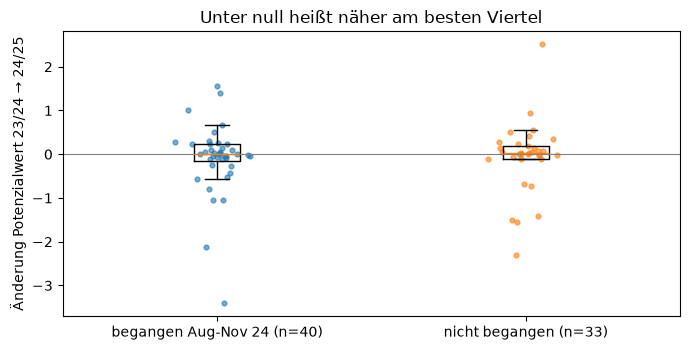

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
gruppen = ["begangen Aug-Nov 24", "nicht begangen"]
daten = [nach.loc[nach["gruppe"] == g, "d_potenzial"].dropna() for g in gruppen]
ax.boxplot(daten, showfliers=False)
for i, d in enumerate(daten, start=1):
    ax.scatter(np.random.default_rng(i).normal(i, 0.05, len(d)), d, s=12,
               alpha=0.6, color="tab:blue" if i == 1 else "tab:orange")
ax.set_xticks([1, 2], [f"{g} (n={len(d)})" for g, d in zip(gruppen, daten)])
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Änderung Potenzialwert 23/24 → 24/25")
ax.set_title("Unter null heißt näher am besten Viertel")
fig.tight_layout()
plt.show()

- Kein Unterschied: Potenzialwert ändert sich in beiden Gruppen im Median kaum.
- Vorher auffällig: begangen zwei von drei danach unauffällig, nicht begangen eine von fünf. Nur eine Beobachtung.
- Passt zu Notebook 03 (Diff-in-Diff nicht signifikant, p um 0,4).

### 4c Gegenprobe: nur 22/23 als Lernwinter

- Kontrolle mit 22/23 allein (41 Stationen), weil 23/24 oben zugleich Lern- und Vorher-Winter ist.

In [10]:
grenzen_alt = nv.grenzen_lernen(tab, kz, ref_aus, winter=["22/23"])
fest_alt = nv.grenzen_anwenden(tab, grenzen_alt)
fest_alt = fest_alt[~fest_alt["meter"].isin(ref_aus)]
print("Auffällig je Winter:",
      fest_alt.groupby("winter")["auffaellig"].sum().to_dict())
tabelle_alt, p_alt = vorher_test(fest_alt)
display(tabelle_alt.round(2))
print("Vorher, p-Werte:", {k: round(v, 2) for k, v in p_alt.items()})
nach_alt, p_nach_alt = nachher_test(fest_alt)
print("Nachher, p-Werte:", {k: round(v, 2) for k, v in p_nach_alt.items()})

Auffällig je Winter: {'22/23': 6, '23/24': 9, '24/25': 12, '25/26': 0}


,n,anteil_auffaellig,anteil_potenzial_hoch,potenzialwert_median
gruppe,,,,
begangen mit Befund,27,0.11,0.22,1.10
begangen ohne Befund,26,0.04,0.04,0.87
nie begangen,32,0.16,0.19,0.75


Vorher, p-Werte: {'auffaellig': np.float64(0.61), 'potenzial': np.float64(0.1), 'potenzialwert': np.float64(0.42)}
Nachher, p-Werte: {'d_score': np.float64(0.58), 'd_potenzial': np.float64(0.75)}


- Auffälligkeit unverändert. Beim Potenzial 22 % gegen 4 % Potenzial hoch für begangene mit und ohne Befund (p = 0,10), nie begangene 19 %. Nur ein schwacher Hinweis.

## Zusammenfassung & Bewertung

- Umgesetzt im Stationsblatt, in der Statustabelle (`potenzial`, `potenzial_score`, `groesste_luecke`, `bw_abstand_*`) und im Bericht von `python -m src.aktualisieren`. Priorität unverändert.
- Belastbar: Die typische Station liegt deutlich hinter den besten, Luft nach oben gibt es im ganzen Netz. Die Rangfolge ändert sich aber kaum (Rangkorrelation 0,99), neu sind physikalische Einheiten und eine weichere Stufe.
- Schwach: Der eingefrorene Maßstab sagt weder Befunde vorher noch zeigt er eine Verbesserung nach den Begehungen. Bei etwa 50 begangenen Stationen und Freitext-Labels kein Beleg gegen die Begehungen, aber die Winterkennzahlen bilden die Befunde nicht ab.
- Offen: Stufengrenzen, Potenzial in der Netzkarte, Nachher-Test mit Winter 25/26, sobald Daten von mehr als vier Stationen vorliegen.